In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import glob

from itertools import combinations
import sys
from statsmodels.stats.multitest import multipletests
from scipy.stats import norm
import os

## Prepare PSI-expression table

In [2]:
%%time
dtype = {'src':'category','event_id':"category", 'sample_id':"category", 'num':float, 'denom':float}
file = '../../../arkuda_backup/unproductive_splicing/data/TCGA/input/gtex_psi/ensembl_chess_prefiltered.psi'
psi = pd.read_csv(file,index_col=[0],comment='#',dtype=dtype)

CPU times: total: 30.1 s
Wall time: 30.2 s


In [3]:
meta = '../../../arkuda_backup/unproductive_splicing/data/TCGA/input/metadata/GTEx.tsv'
meta = pd.read_csv(meta,sep='\t')

In [4]:
psi = meta[['sample_id','experiment','histological_type']].drop_duplicates().merge(psi)

CPU times: total: 1min 23s
Wall time: 1min 23s


''

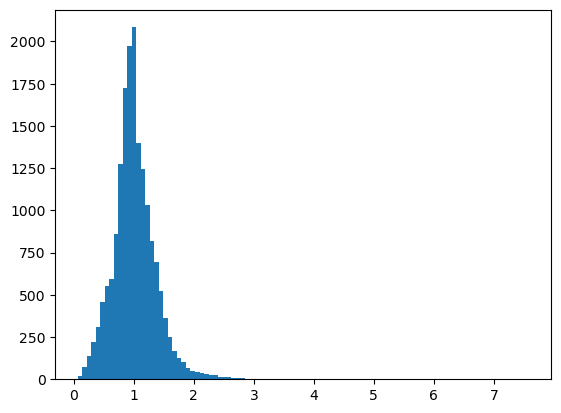

In [5]:
%%time
from collections import defaultdict
dtype = defaultdict(lambda: int)
dtype['gene_id'] = str
expr = pd.read_csv('../../../arkuda_backup/expression/raw/GTEx/raw_count_protein_coding.csv',
                   index_col=[0],dtype=dtype)
expr+=1

ref = np.log(expr).apply(np.mean,1).apply(np.exp)
sf = expr.div(ref,axis=0).apply(np.median)

plt.hist(sf,bins=100)
''

In [6]:
samples = list(set(expr.columns)&set(meta.clinical_sample_id))
ren = meta[meta.clinical_sample_id.isin(samples)].set_index('clinical_sample_id').sample_id
expr = expr.div(sf,axis=1)
expr = expr[ren.index].rename(columns=ren)

In [7]:
catalog = pd.read_csv('./use_catalog/filtered_catalog.tsv',sep='\t')

In [8]:
cat = catalog[['src','event_id','gene_id']].drop_duplicates().copy()
eg = psi[['src','event_id']].drop_duplicates().merge(cat)

In [9]:
ind = expr.index.intersection(eg.gene_id.unique())

In [10]:
elong = expr.loc[ind].reset_index().melt(id_vars='gene_id',var_name='sample_id',value_name='expr')

In [11]:
del expr
import gc
gc.collect()

0

In [12]:
psi = psi.set_index(['src','event_id'])
psi['gene_id'] = psi.index.map(eg.set_index(['src','event_id']).gene_id)

In [13]:
psi.experiment = psi.experiment.astype('category')
psi.histological_type = psi.histological_type.astype('category')

In [14]:
#this and previous is needed because pd.merge is memory-inefficient
psi = psi.reset_index().set_index(['sample_id','gene_id'])
elong = elong.set_index(['sample_id','gene_id'])

In [15]:
psi['expr'] = psi.index.map(elong.expr)

In [16]:
psi = psi.reset_index()

In [17]:
%%time
import pickle
with open('psi_expression_gtex.pkl', 'wb') as f:
    pickle.dump(psi, f)

CPU times: total: 5.95 s
Wall time: 46.5 s
